# Notebook 01: Data Preparation, Exploration & Next-Token Alignment
## DSL 504 — NLP Group Assignment 2 | Question 4: The Plot-Twist Generator

This notebook documents the end-to-end data preparation pipeline for **Question 4: The Plot-Twist Generator**:
1. **Story-Level Splitting**: Extracting non-overlapping story splits (20,000 train, 1,000 validation, 1,000 test) from `roneneldan/TinyStories` via Hugging Face.
2. **Text Normalization & Tokenization**: Normalizing punctuation, handling quotes, lowercasing, and preserving sentence structure.
3. **Vocabulary Construction**: Building a deterministic shared vocabulary on the training split with special tokens (`<PAD>`, `<UNK>`, `<BOS>`, `<EOS>`).
4. **Sequence Chunking & Input-Target Alignment**: Creating next-token pairs $x_t \to y_t = x_{t+1}$ while strictly preserving individual story boundaries.
5. **Exploratory Data Analysis**: Visualizing story length distributions, vocabulary frequencies, and OOV rates.
6. **Theoretical Foundations**: Explaining why story boundaries must be preserved and how padding is masked during training.

In [1]:
import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import torch

# Ensure project root is in path
project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.append(project_root)

from src.utils import set_seed, CONFIG
from src.data_prep import (
    load_and_split_tinystories,
    clean_and_tokenize,
    Vocabulary,
    StoryLMDataset,
    get_dataloaders,
    SPECIAL_TOKENS,
)

set_seed(CONFIG.get("seed", 42))
print("Environment initialized and random seeds locked to:", CONFIG.get("seed", 42))

C:\Tech-notes-prac-etc\NLP\Group Assignment 2\Question_4\plot_twist_generator\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment initialized and random seeds locked to: 42


### 1. Story-Level Splitting & Dataset Caching

> **Rubric Requirement**: Split the data at the story level before creating training sequences. Do not let overlapping sequences from the same story appear in different splits.

In [2]:
data_dir = os.path.join(project_root, "data")
checkpoints_dir = os.path.join(project_root, "checkpoints")

train_stories, val_stories, test_stories = load_and_split_tinystories(
    num_train=CONFIG.get("train_stories", 20000),
    num_val=CONFIG.get("val_stories", 1000),
    num_test=CONFIG.get("test_stories", 1000),
    seed=CONFIG.get("seed", 42),
    cache_dir=data_dir,
)

print(f"Train stories: {len(train_stories):,}")
print(f"Val stories:   {len(val_stories):,}")
print(f"Test stories:  {len(test_stories):,}")

Loading cached splits from directory: 'C:\Tech-notes-prac-etc\NLP\Group Assignment 2\Question_4\plot_twist_generator\data'...
Successfully loaded cached data: 20000 train, 1000 val, 1000 test stories.
Train stories: 20,000
Val stories:   1,000
Test stories:  1,000


### 2. Text Normalization, Tokenization & Shared Vocabulary Construction

In [3]:
vocab_file = os.path.join(checkpoints_dir, "vocab.json")
if os.path.exists(vocab_file):
    vocab = Vocabulary.load(vocab_file)
    print(f"Loaded existing vocabulary from {vocab_file} (size: {len(vocab):,})")
else:
    vocab = Vocabulary(max_size=CONFIG.get("max_vocab_size", 10000), min_freq=CONFIG.get("min_freq", 2))
    vocab.build_from_stories(train_stories)
    vocab.save(vocab_file)
    print(f"Built vocabulary from train stories (size: {len(vocab):,})")

# Sample tokenization walkthrough
sample_story = train_stories[0]
tokens = clean_and_tokenize(sample_story)
encoded = vocab.encode(sample_story, add_bos=True, add_eos=True)
decoded = vocab.decode(encoded, stop_at_eos=True)

print("\n--- Sample Story Walkthrough ---")
print("Original text preview:", sample_story[:120], "...")
print("Cleaned tokens (first 10):", tokens[:10])
print("Encoded IDs (first 10):", encoded[:10])
print("Reconstructed text:", decoded[:120], "...")

Loaded existing vocabulary from C:\Tech-notes-prac-etc\NLP\Group Assignment 2\Question_4\plot_twist_generator\checkpoints\vocab.json (size: 8,801)

--- Sample Story Walkthrough ---
Original text preview: One day, two kids were playing at the park. They wanted to do something special and unusual.

The first kid said, "Let's ...
Cleaned tokens (first 10): ['one', 'day', ',', 'two', 'kids', 'were', 'playing', 'at', 'the', 'park']
Encoded IDs (first 10): [2, 35, 26, 7, 239, 411, 49, 116, 63, 5]
Reconstructed text: one day, two kids were playing at the park. they wanted to do something special and unusual. the first kid said, " let ' ...


### 3. Out-Of-Vocabulary (OOV) Rate Evaluation

In [4]:
val_oov_rate, val_oov_count, val_total = vocab.compute_oov_rate(val_stories)
test_oov_rate, test_oov_count, test_total = vocab.compute_oov_rate(test_stories)

print(f"Validation OOV Rate: {val_oov_rate:.2f}% ({val_oov_count:,} / {val_total:,} tokens)")
print(f"Test OOV Rate:       {test_oov_rate:.2f}% ({test_oov_count:,} / {test_total:,} tokens)")

Validation OOV Rate: 0.18% (383 / 213,456 tokens)


Test OOV Rate:       0.22% (405 / 185,295 tokens)


### 4. Sequence Length & Corpus Distribution Visualizations

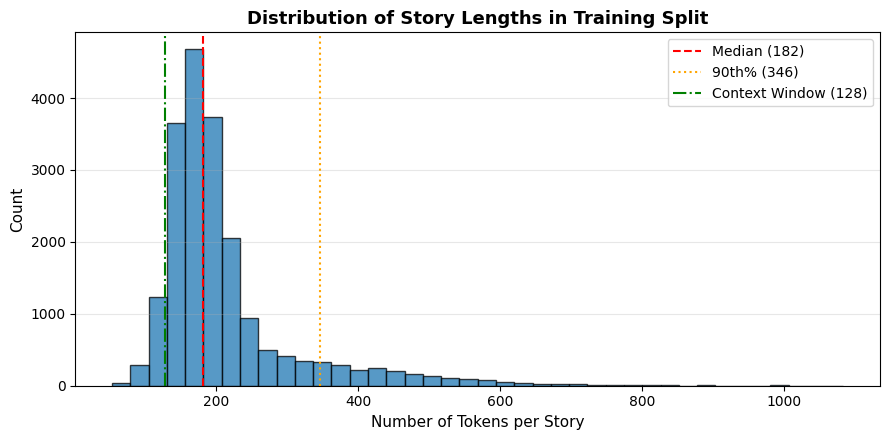

In [5]:
train_lens = [len(clean_and_tokenize(s)) for s in train_stories]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(train_lens, bins=40, color="#1f77b4", alpha=0.75, edgecolor="black")
ax.axvline(np.median(train_lens), color="red", linestyle="--", label=f"Median ({np.median(train_lens):.0f})")
ax.axvline(np.percentile(train_lens, 90), color="orange", linestyle=":", label=f"90th% ({np.percentile(train_lens, 90):.0f})")
ax.axvline(CONFIG.get("max_seq_len", 128), color="green", linestyle="-.", label=f"Context Window ({CONFIG.get('max_seq_len', 128)})")
ax.set_title("Distribution of Story Lengths in Training Split", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Tokens per Story", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Next-Token Input-Target Verification & DataLoader Inspection

> For every training sequence chunk $c = (t_0, t_1, \dots, t_L)$:
> - **Input** $x = (t_0, t_1, \dots, t_{L-1})$
> - **Target** $y = (t_1, t_2, \dots, t_L)$
> - Alignment condition: $y_t = x_{t+1}$.

In [6]:
train_loader, val_loader, test_loader, _ = get_dataloaders(
    train_stories=train_stories,
    val_stories=val_stories,
    test_stories=test_stories,
    vocab=vocab,
    max_seq_len=CONFIG.get("max_seq_len", 128),
    batch_size=CONFIG.get("batch_size", 64),
)

x_batch, y_batch, lengths = next(iter(train_loader))
print(f"Batch x shape: {x_batch.shape}")
print(f"Batch y shape: {y_batch.shape}")
print(f"First 5 lengths in batch: {lengths[:5].tolist()}")

# Check target offset
first_len = lengths[0].item()
assert (x_batch[0, 1:first_len] == y_batch[0, :first_len-1]).all(), "Target is not shifted input!"
print("\n[PASSED] Strict next-token alignment verified: y[t] == x[t+1] across non-padded sequence!")

Batch x shape: torch.Size([64, 128])
Batch y shape: torch.Size([64, 128])
First 5 lengths in batch: [128, 128, 43, 128, 128]

[PASSED] Strict next-token alignment verified: y[t] == x[t+1] across non-padded sequence!


### 6. Required Theoretical Justifications (Rubric: Part 1)

#### 1. Why Story Boundaries Must Be Preserved
In language modeling, concatenating independent documents into one uninterrupted stream allows the final recurrent state $h_T$ of Story $A$ to condition the initial tokens of Story $B$. This induces **spurious cross-narrative transition probabilities** (e.g., blending a detective mystery with a story about a flying squirrel) and destroys the clean start-of-sequence distribution $P(w_1 \mid \langle\text{BOS}\rangle)$. By chunking strictly within individual story boundaries, our models learn authentic narrative arcs, character permanence, and proper story termination via $\langle\text{EOS}\rangle$.

#### 2. How Padding is Handled During Training
1. **Right-Padding**: Variable-length story sequences in each mini-batch are padded with $\langle\text{PAD}\rangle$ (ID = 0) up to the maximum length of that batch.
2. **Embedding Zeroing**: In PyTorch, `nn.Embedding(..., padding_idx=0)` ensures that the embedding vector for $\langle\text{PAD}\rangle$ is initialized to zero and receives zero gradient updates throughout training.
3. **Loss Masking**: `nn.CrossEntropyLoss(ignore_index=0)` masks out all positions where the target is $\langle\text{PAD}\rangle$. Consequently, padded tokens contribute zero loss and zero gradient, preventing artificial loss/perplexity deflation.